# Демонстрация танкового агента

Запустите ячейки по порядку. Агент использует заданную стратегию, а не обученную модель:
выходит на одну строку или колонку с противником, поворачивается к нему и стреляет.
В этой среде противник неподвижен, а попадание рассчитывается сразу при выстреле.


In [27]:
# Выполните при первом запуске в новом окружении.
# %pip использует Python текущего ядра ноутбука.
%pip install -e ../..


Obtaining file:///C:/Users/vladn/Documents/RL%20with%20jack%20the%20dog/RL_with_jack_the_dog
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Building editable for jack_the_dog (pyproject.toml): started
  Building editable for jack_the_dog (pyproject.toml): finished with status 'done'
  Created wheel for jack_the_dog: filename=jack_the_dog-0.1.0-0.editable-py3-none-any.whl size=1391 sha256=16f8a994d4f6d148c81d8fc14bdffb1b98661068e2df36a3a267d35f27fcab23
  Stored in directory: C:\Users\vladn\AppData\Local\Temp\pip-ephem-wheel-cache-jjxuc8id\wheel


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
from io import BytesIO

import numpy as np
from PIL import Image as PILImage
from IPython.display import Image, display
from gymnasium.utils.env_checker import check_env

from fight_env import FightGridEnv, ACTION, Direction

env = FightGridEnv(render_mode="rgb_array")
scale = 64 / env.cell_size
for name, texture in vars(env).copy().items():
    if name.endswith('_texture') and isinstance(texture, PILImage.Image):
        size = tuple(max(1, round(value * scale)) for value in texture.size)
        setattr(env, name, texture.resize(size, PILImage.Resampling.LANCZOS))
env.cell_size = 64


In [ ]:
def agent_action(observation):
    x, y, direction, enemy_x, enemy_y = map(int, observation)

    if x == enemy_x:
        move = ACTION.RIGHT if enemy_y > y else ACTION.LEFT
        aim = Direction.RIGHT if enemy_y > y else Direction.LEFT
    elif y == enemy_y:
        move = ACTION.DOWN if enemy_x > x else ACTION.TOP
        aim = Direction.DOWN if enemy_x > x else Direction.UP
    else:
        return ACTION.DOWN if enemy_x > x else ACTION.TOP

    return ACTION.SHOT if direction == aim else move


def run_episode(env, seed, collect_frames=False):
    observation, _ = env.reset(seed=seed)
    frames = [env.render()] if collect_frames else []
    history = []
    total_reward = 0.0
    terminated = truncated = False

    for step in range(1, env.max_steps + 1):
        action = agent_action(observation)
        observation, reward, terminated, truncated, _ = env.step(action)
        total_reward += reward
        history.append((step, ACTION(action).name, reward, total_reward))
        if collect_frames:
            frames.append(env.render())
        if terminated or truncated:
            break

    return frames, history, terminated, truncated


## Один эпизод

Измените `SEED`, чтобы получить другую начальную расстановку.
Анимация показывает начальное состояние, каждое действие и уничтоженную цель.


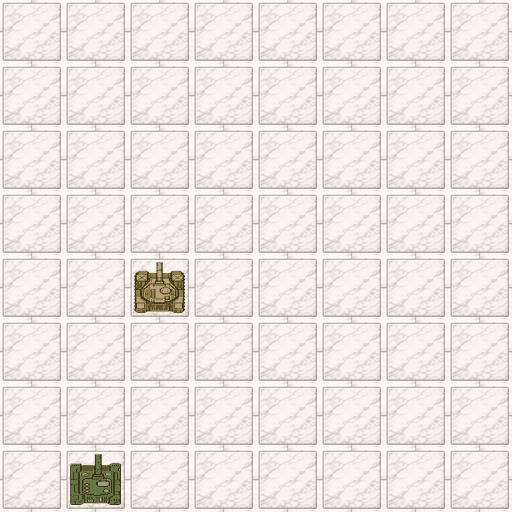

 Шаг  Действие    Награда    Сумма
   1  TOP           -0.01    -0.01
   2  TOP           -0.01    -0.02
   3  TOP           -0.01    -0.03
   4  RIGHT         -0.01    -0.04
   5  SHOT          10.00     9.96
Цель уничтожена!


In [40]:
SEED = 31
FRAME_DURATION_MS = 450

frames, history, terminated, truncated = run_episode(env, SEED, collect_frames=True)

images = [PILImage.fromarray(frame) for frame in frames]
animation = BytesIO()
images[0].save(
    animation,
    format="GIF",
    save_all=True,
    append_images=images[1:],
    duration=[FRAME_DURATION_MS] * (len(images) - 1) + [1800],
    loop=0,
)
display(Image(data=animation.getvalue(), format="gif"))

print(f"{'Шаг':>4}  {'Действие':<10} {'Награда':>8} {'Сумма':>8}")
for step, action, reward, total in history:
    print(f"{step:>4}  {action:<10} {reward:>8.2f} {total:>8.2f}")
print("Цель уничтожена!" if terminated else "Достигнут лимит шагов.")


## Проверка на разных расстановках

Проверим стратегию на 100 начальных состояниях без рендеринга.


In [31]:
results = [run_episode(env, seed) for seed in range(100)]
successes = sum(terminated for _, _, terminated, _ in results)
lengths = [len(history) for _, history, _, _ in results]
returns = [sum(row[2] for row in history) for _, history, _, _ in results]
print(f"Успешные эпизоды: {successes}/{len(results)}")
print(f"Среднее число шагов: {np.mean(lengths):.2f}")
print(f"Средняя суммарная награда: {np.mean(returns):.2f}")
env.close()


Успешные эпизоды: 100/100
Среднее число шагов: 4.50
Средняя суммарная награда: 9.97
